# Fluo-N2DL-HeLa Ultrack - StarDist Benchmark Comparison


## Environment and paths

This notebook follows Ultrack's published-style 2D worklow on `Fluo-N2DL-HeLa1:

1. It normalizes each raw image
2. Generate instance labels with the pretrained StarDist `2D_versatile_fluo` model
3. Convert the labels to foreground and contour maps with `labels_to_contours` from the StarDist model
4. Run Ultrack segmentation, linking, solving and export


A test run validation is first done with 5 frames (frames 12 - 16), similar to the ultrack subset test. 

Gold annotations are used only for inspection and are never supplied to StarDist or Ultrack


## Environment and paths

The Python (Ultrack + StarDist) kernel is used for this notebook's workflow. Before starting the kernel, define these variables in the cluster environment

```bash
export CTC_ROOT=/path/to/DSC_CTC
export ULTRACK_RUN_ROOT=/path/to/DSC_CTC/runs/ultrack
export KERAS_HOME=/path/to/DSC_CTC/models/keras-cache
```

`KERAS_HOME` must be set before importing TensorFlow or StarDist. If a variable is missing, set it and restart the notebook kern

In [3]:
import os
from pathlib import Path

required_variables = ["CTC_ROOT", "ULTRACK_RUN_ROOT", "KERAS_HOME"]
missing_variables = [name for name in required_variables if not os.environ.get(name)]
if missing_variables:
    raise RuntimeError(
        f"Set these variables and restart the kernel: {missing_variables}"
    )

CTC_ROOT = Path(os.environ["CTC_ROOT"]).expanduser()
ULTRACK_RUN_ROOT = Path(os.environ["ULTRACK_RUN_ROOT"]).expanduser()
KERAS_HOME = Path(os.environ["KERAS_HOME"]).expanduser()
print(f"CTC root: {CTC_ROOT}")
print(f"Ultrack run root: {ULTRACK_RUN_ROOT}")
print(f"Keras model cache: {KERAS_HOME}")

CTC root: /net/spaces/clinic/CLS/DSC_CTC
Ultrack run root: /net/spaces/clinic/CLS/DSC_CTC/runs/ultrack
Keras model cache: /net/spaces/clinic/CLS/DSC_CTC/models/keras-cache


In [4]:
import sys
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from stardist.models import StarDist2D
from tqdm.auto import tqdm
from ultrack import MainConfig, Tracker
from ultrack.imgproc import normalize
from ultrack.utils import labels_to_contours

print(f"Python: {sys.version.split()[0]}")
for package in ["tensorflow", "stardist", "ultrack"]:
    print(f"{package}: {version(package)}")

I0000 00:00:1792552457.466338 1966018 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792552457.515995 1966018 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792552460.176664 1966018 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
auto.py (21): IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


Python: 3.12.15
tensorflow: 2.21.0
stardist: 0.9.2
ultrack: 0.8.0


## Run Configuration

- Set `RUN_MODE = "subset"` until the StarDist labels and Ultrack outputs have been inspected.

- The full benchmark mode uses all 92 frames and writes to a different run directory.

In [5]:
DATASET = "Fluo-N2DL-HeLa"
SEQUENCE = "02"
RUN_MODE = "full"  # Change to "full" only after validating the subset.

if RUN_MODE == "subset":
    FRAME_START, FRAME_STOP = 12, 17
    RUN_NAME = "hela-seq02-t012-016-stardist"
    CTC_OUTPUT_NAME = "subset_RES"
elif RUN_MODE == "full":
    FRAME_START, FRAME_STOP = 0, None
    RUN_NAME = "hela-seq02-full-stardist"
    CTC_OUTPUT_NAME = f"{SEQUENCE}_RES"
else:
    raise ValueError(f"Unknown RUN_MODE: {RUN_MODE}")

In [6]:
DATASET_ROOT = CTC_ROOT / "ctc" / DATASET
RAW_DIR = DATASET_ROOT / SEQUENCE
GT_SEG_DIR = DATASET_ROOT / f"{SEQUENCE}_GT" / "SEG"
RUN_DIR = ULTRACK_RUN_ROOT / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

if not RAW_DIR.is_dir():
    raise FileNotFoundError(f"Raw image directory does not exist: {RAW_DIR}")

print(f"Raw images: {RAW_DIR}")
print(f"Gold SEG reference: {GT_SEG_DIR}")
print(f"Run directory: {RUN_DIR}")

Raw images: /net/spaces/clinic/CLS/DSC_CTC/ctc/Fluo-N2DL-HeLa/02
Gold SEG reference: /net/spaces/clinic/CLS/DSC_CTC/ctc/Fluo-N2DL-HeLa/02_GT/SEG
Run directory: /net/spaces/clinic/CLS/DSC_CTC/runs/ultrack/hela-seq02-full-stardist


## Load raw microscopy images

Only raw `t*.tif` images are loaded as model inputs.


In [7]:
all_raw_paths = sorted(RAW_DIR.glob("t*.tif"))
raw_paths = all_raw_paths[FRAME_START:FRAME_STOP]
if not raw_paths:
    raise ValueError("The selected frame range contains no raw images.")

raw_images = np.stack([tifffile.imread(path) for path in raw_paths])
frame_numbers = [int(path.stem.removeprefix("t")) for path in raw_paths]
print(f"Files: {raw_paths[0].name} to {raw_paths[-1].name}")
print(f"Array shape: {raw_images.shape}")
print(f"Data type: {raw_images.dtype}")

Files: t000.tif to t091.tif
Array shape: (92, 700, 1100)
Data type: uint16


## Generate StarDist instance labels

The settings below follow Ultrack's official 2D StarDist example.

Each frame is normalized independently, then segmented with the pretrained `2D_versatile_fluo` model.

In [8]:
model = StarDist2D.from_pretrained("2D_versatile_fluo")
print("Loaded pretrained StarDist model: 2D_versatile_fluo")

Found model '2D_versatile_fluo' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.
Loaded pretrained StarDist model: 2D_versatile_fluo


E0000 00:00:1792552494.961855 1966018 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [9]:
stardist_labels = np.zeros_like(raw_images, dtype=np.int32)
start_time = time.perf_counter()

for index, image in enumerate(tqdm(raw_images, desc="StarDist inference")):
    # normalizing each frame
    normalized = normalize(image, gamma=1.0)
    labels, _ = model.predict_instances_big(
        normalized, "YX", block_size=560, min_overlap=96, show_progress=False
    )
    stardist_labels[index] = labels

stardist_runtime = time.perf_counter() - start_time
label_counts = [np.unique(labels).size - 1 for labels in stardist_labels]
print(f"StarDist runtime: {stardist_runtime:.2f} seconds")
print(dict(zip(frame_numbers, label_counts)))

StarDist inference:   0%|          | 0/92 [00:00<?, ?it/s]

effective: block_size=(560, 560), min_overlap=(96, 96), context=(96, 96)


StarDist inference:   1%|          | 1/92 [00:01<02:44,  1.81s/it]

effective: block_size=(560, 560), min_overlap=(96, 96), context=(96, 96)


StarDist inference:   2%|▏         | 2/92 [00:03<02:12,  1.48s/it]

...

effective: block_size=(560, 560), min_overlap=(96, 96), context=(96, 96)


StarDist inference:  99%|█████████▉| 91/92 [02:10<00:01,  1.47s/it]

effective: block_size=(560, 560), min_overlap=(96, 96), context=(96, 96)


StarDist inference: 100%|██████████| 92/92 [02:12<00:00,  1.44s/it]


StarDist runtime: 132.27 seconds
{0: 131, 1: 142, 2: 141, 3: 142, 4: 151, 5: 156, 6: 159, 7: 160, 8: 167, 9: 171, 10: 174, 11: 176, 12: 183, 13: 182, 14: 180, 15: 183, 16: 187, 17: 183, 18: 190, 19: 195, 20: 195, 21: 202, 22: 208, 23: 213, 24: 219, 25: 206, 26: 214, 27: 226, 28: 223, 29: 222, 30: 234, 31: 240, 32: 240, 33: 252, 34: 256, 35: 262, 36: 259, 37: 277, 38: 285, 39: 287, 40: 299, 41: 303, 42: 313, 43: 327, 44: 311, 45: 308, 46: 315, 47: 318, 48: 314, 49: 320, 50: 324, 51: 324, 52: 327, 53: 337, 54: 341, 55: 346, 56: 348, 57: 347, 58: 347, 59: 358, 60: 359, 61: 365, 62: 363, 63: 365, 64: 367, 65: 371, 66: 369, 67: 368, 68: 373, 69: 374, 70: 375, 71: 376, 72: 378, 73: 374, 74: 377, 75: 373, 76: 376, 77: 378, 78: 377, 79: 373, 80: 376, 81: 380, 82: 380, 83: 387, 84: 381, 85: 378, 86: 384, 87: 378, 88: 379, 89: 373, 90: 379, 91: 376}


In [10]:
STARDIST_LABEL_DIR = RUN_DIR / "stardist_labels"
STARDIST_LABEL_DIR.mkdir(parents=True, exist_ok=True)

for frame, labels in zip(frame_numbers, stardist_labels):
    tifffile.imwrite(
        STARDIST_LABEL_DIR / f"mask{frame:03d}.tif",
        labels.astype(np.uint16),
    )

print(f"Saved StarDist labels to: {STARDIST_LABEL_DIR}")

Saved StarDist labels to: /net/spaces/clinic/CLS/DSC_CTC/runs/ultrack/hela-seq02-full-stardist/stardist_labels


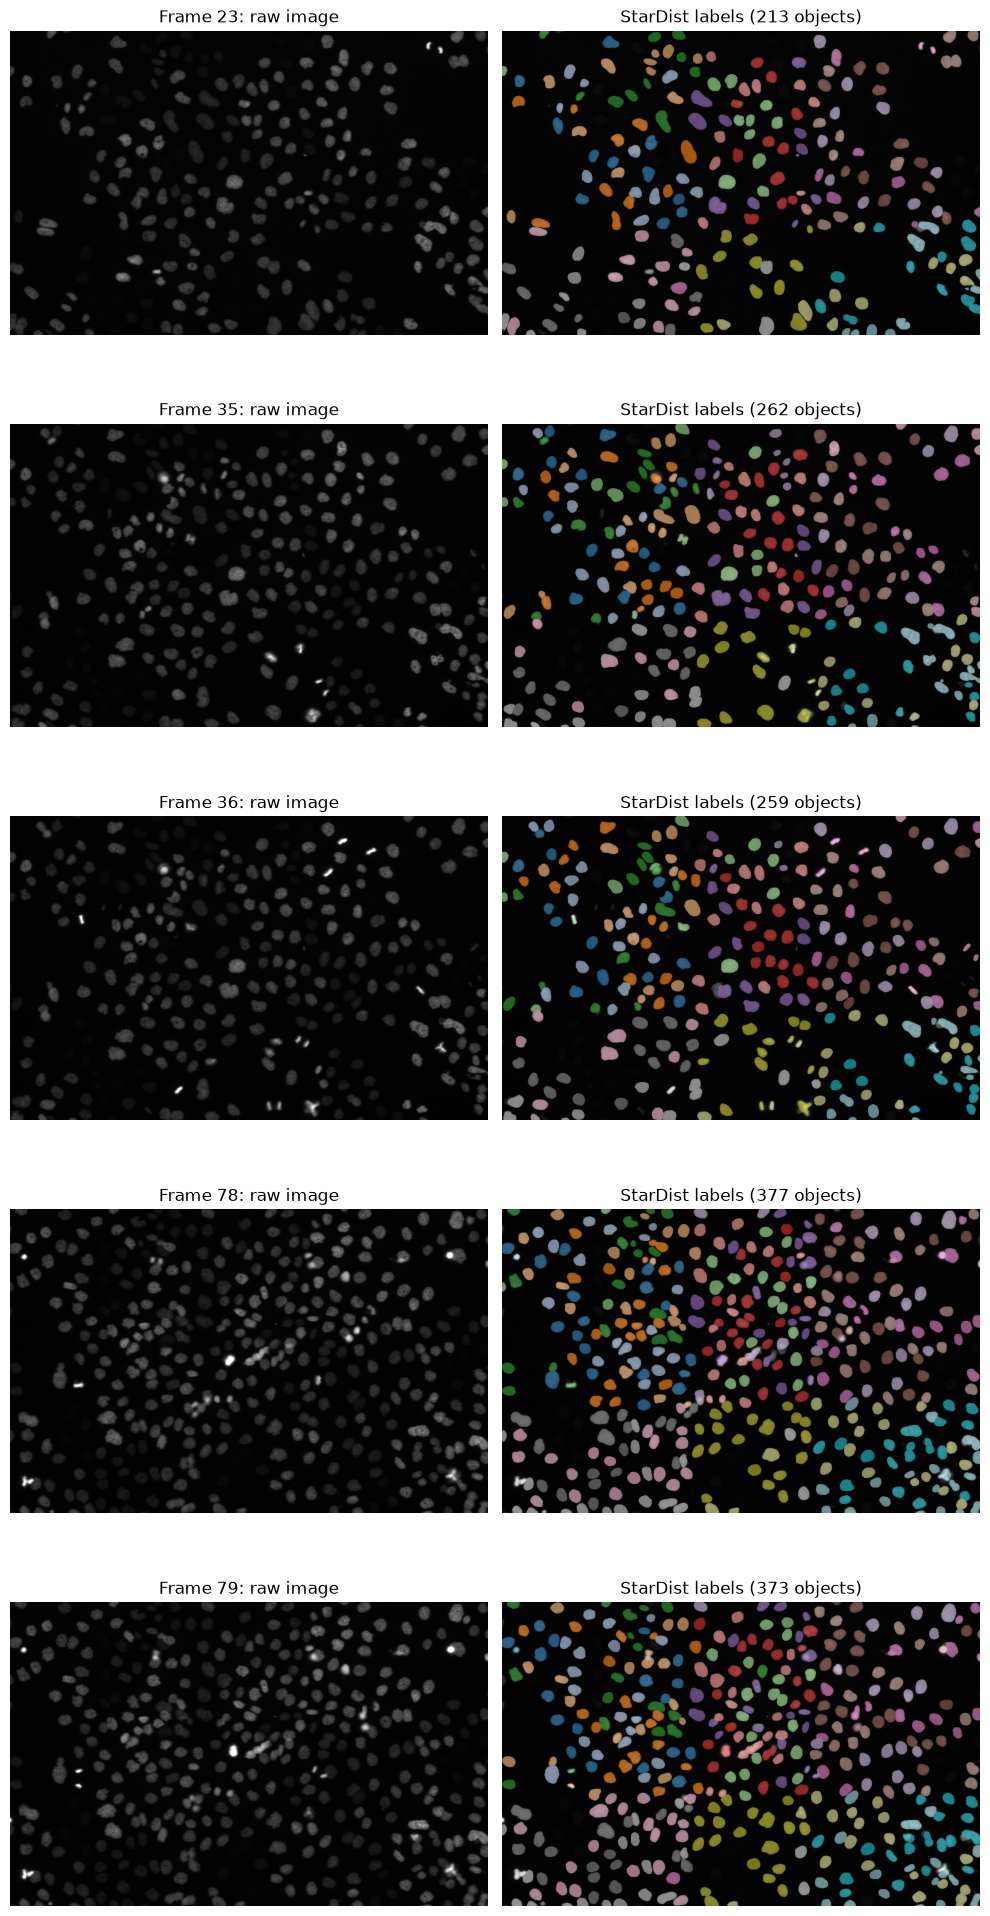

In [11]:
display_frames = [23, 35, 36, 78, 79]
display_indices = [
    i for i, frame in enumerate(frame_numbers) if frame in display_frames
]
figure, axes = plt.subplots(
    len(display_indices), 2, figsize=(10, 4 * len(display_indices)), squeeze=False
)

for row, index in zip(axes, display_indices):
    labels = stardist_labels[index]
    row[0].imshow(raw_images[index], cmap="gray")
    row[0].set_title(f"Frame {frame_numbers[index]}: raw image")
    row[1].imshow(raw_images[index], cmap="gray")
    row[1].imshow(np.ma.masked_where(labels == 0, labels), cmap="tab20", alpha=0.6)
    row[1].set_title(f"StarDist labels ({label_counts[index]} objects)")
    for axis in row:
        axis.axis("off")
plt.tight_layout()

In [14]:
# fig.savefig(
#     "../../docs/images/foreground-contours.png",
#     dpi=150,
#     bbox_inches="tight",
# )

## Inspect StarDist labels against sparse gold segmentation

This is a qualitative checkpoint only. 

Colors identify separate label values; they do not represent cell type, confidence, or tracking identity. Frame 16 is expected to have no gold SEG file.

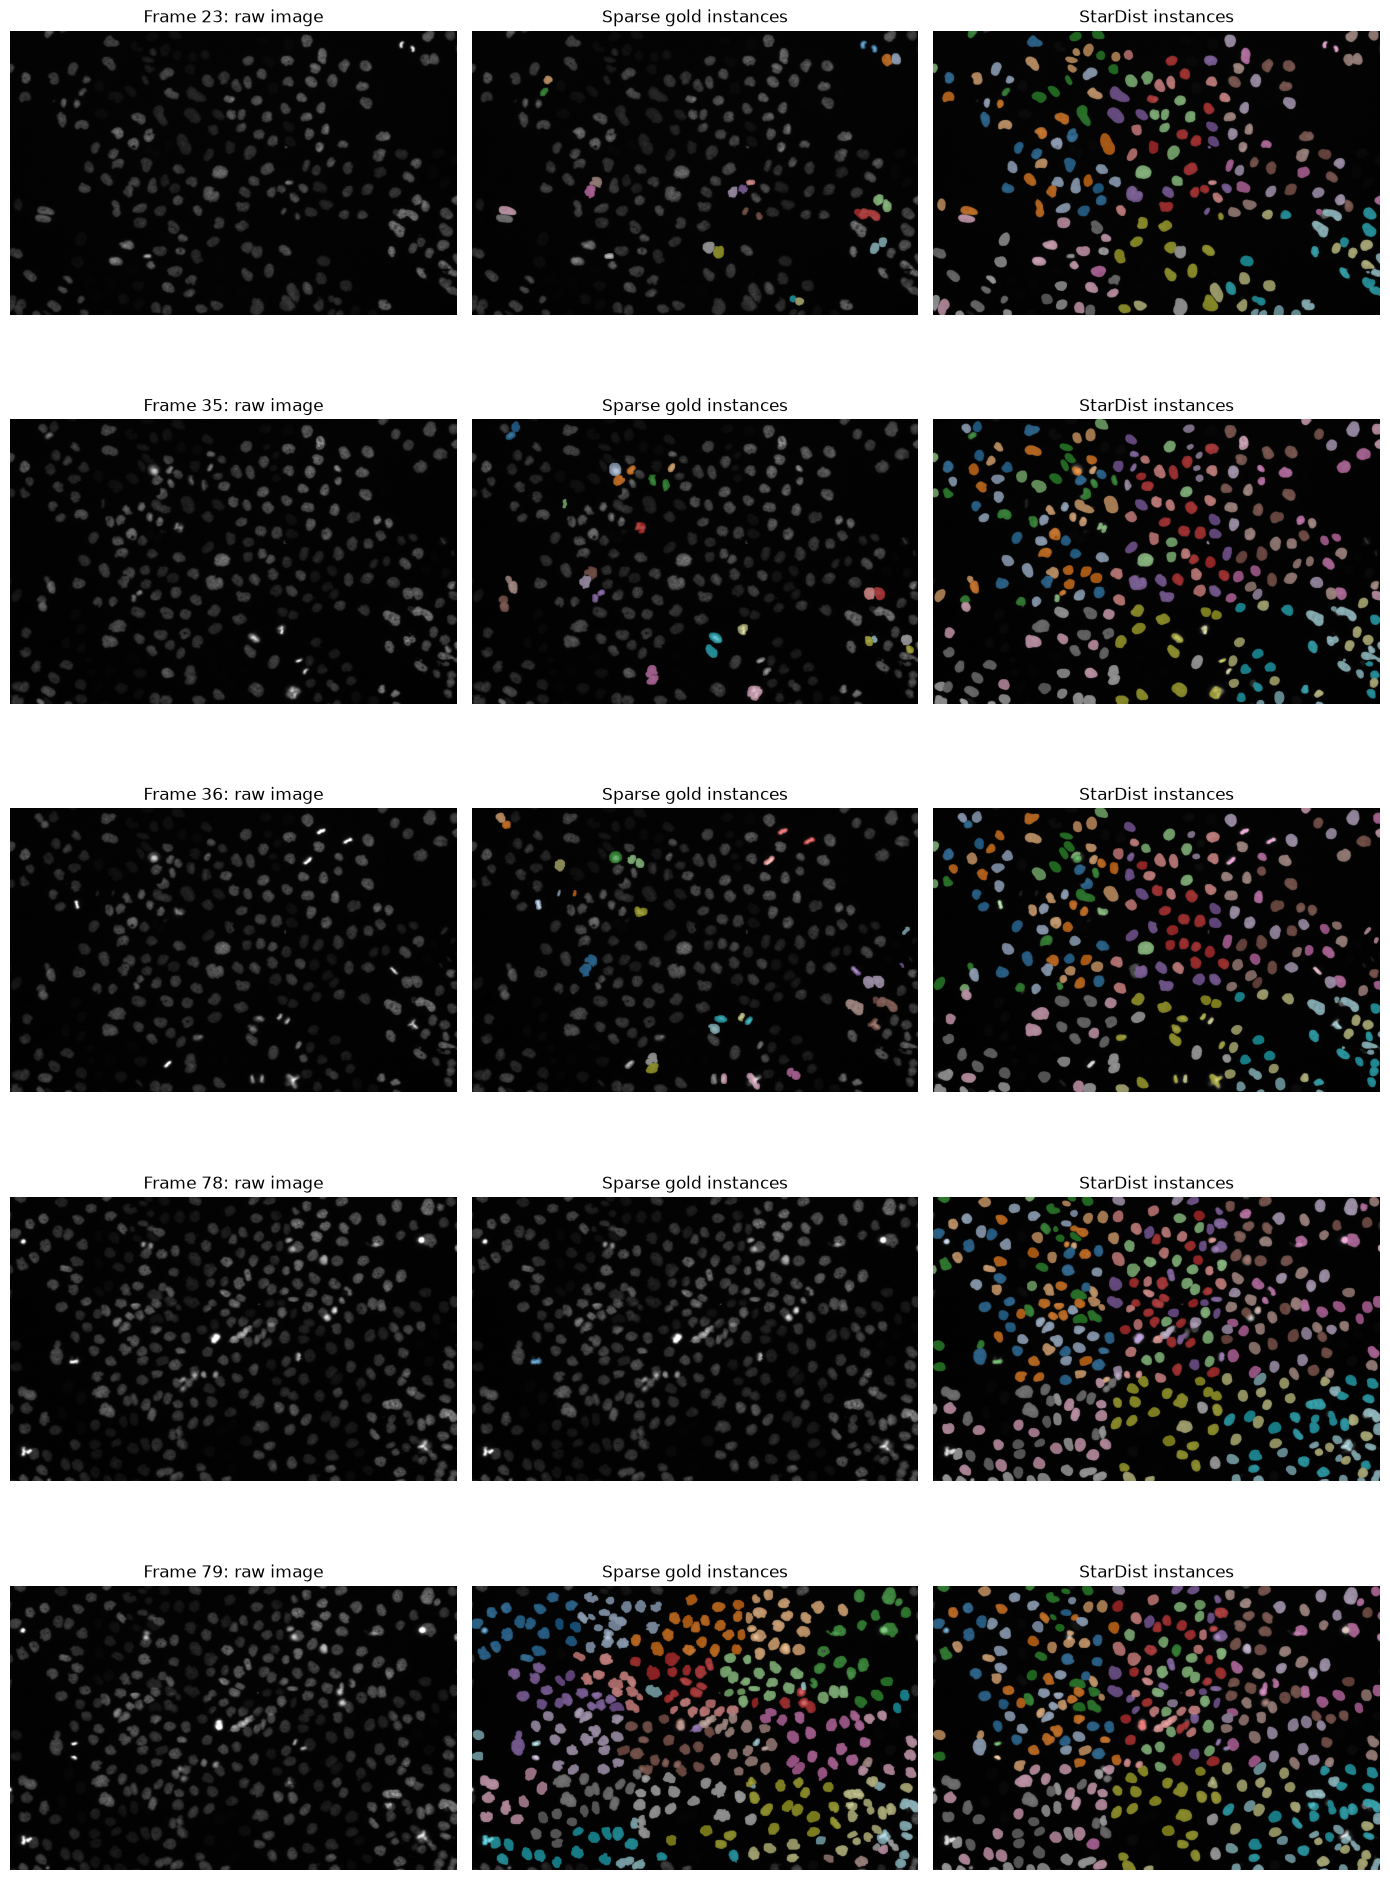

In [12]:
gold_rows = []
for index in display_indices:
    frame = frame_numbers[index]
    gt_path = GT_SEG_DIR / f"man_seg{frame:03d}.tif"
    if gt_path.is_file():
        gold_rows.append((index, frame, gt_path))
    else:
        print(f"No gold SEG file for frame {frame}.")

figure, axes = plt.subplots(
    len(gold_rows), 3, figsize=(14, 4 * len(gold_rows)), squeeze=False
)
for row, (index, frame, gt_path) in zip(axes, gold_rows):
    gold = tifffile.imread(gt_path)
    predicted = stardist_labels[index]
    for axis in row:
        axis.imshow(raw_images[index], cmap="gray")
        axis.axis("off")
    row[0].set_title(f"Frame {frame}: raw image")
    row[1].imshow(np.ma.masked_where(gold == 0, gold), cmap="tab20", alpha=0.6)
    row[1].set_title("Sparse gold instances")
    row[2].imshow(
        np.ma.masked_where(predicted == 0, predicted), cmap="tab20", alpha=0.6
    )
    row[2].set_title("StarDist instances")
plt.tight_layout()

## Convert StarDist labels to Ultrack inputs

The official example uses `labels_to_contours(..., sigma=4.0)`. The resulting foreground and contour arrays, rather than the gold annotations, are passed to Ultrack.

In [13]:
foreground, contours = labels_to_contours(stardist_labels, sigma=4.0)
foreground = np.asarray(foreground).astype(bool)
contours = np.asarray(contours).astype(np.float32)

print(f"Foreground: {foreground.shape}, {foreground.dtype}")
print(f"Contours: {contours.shape}, {contours.dtype}")

Converting labels to contours: 100%|██████████| 92/92 [00:05<00:00, 18.14it/s]


Foreground: (92, 700, 1100), bool
Contours: (92, 700, 1100), float32


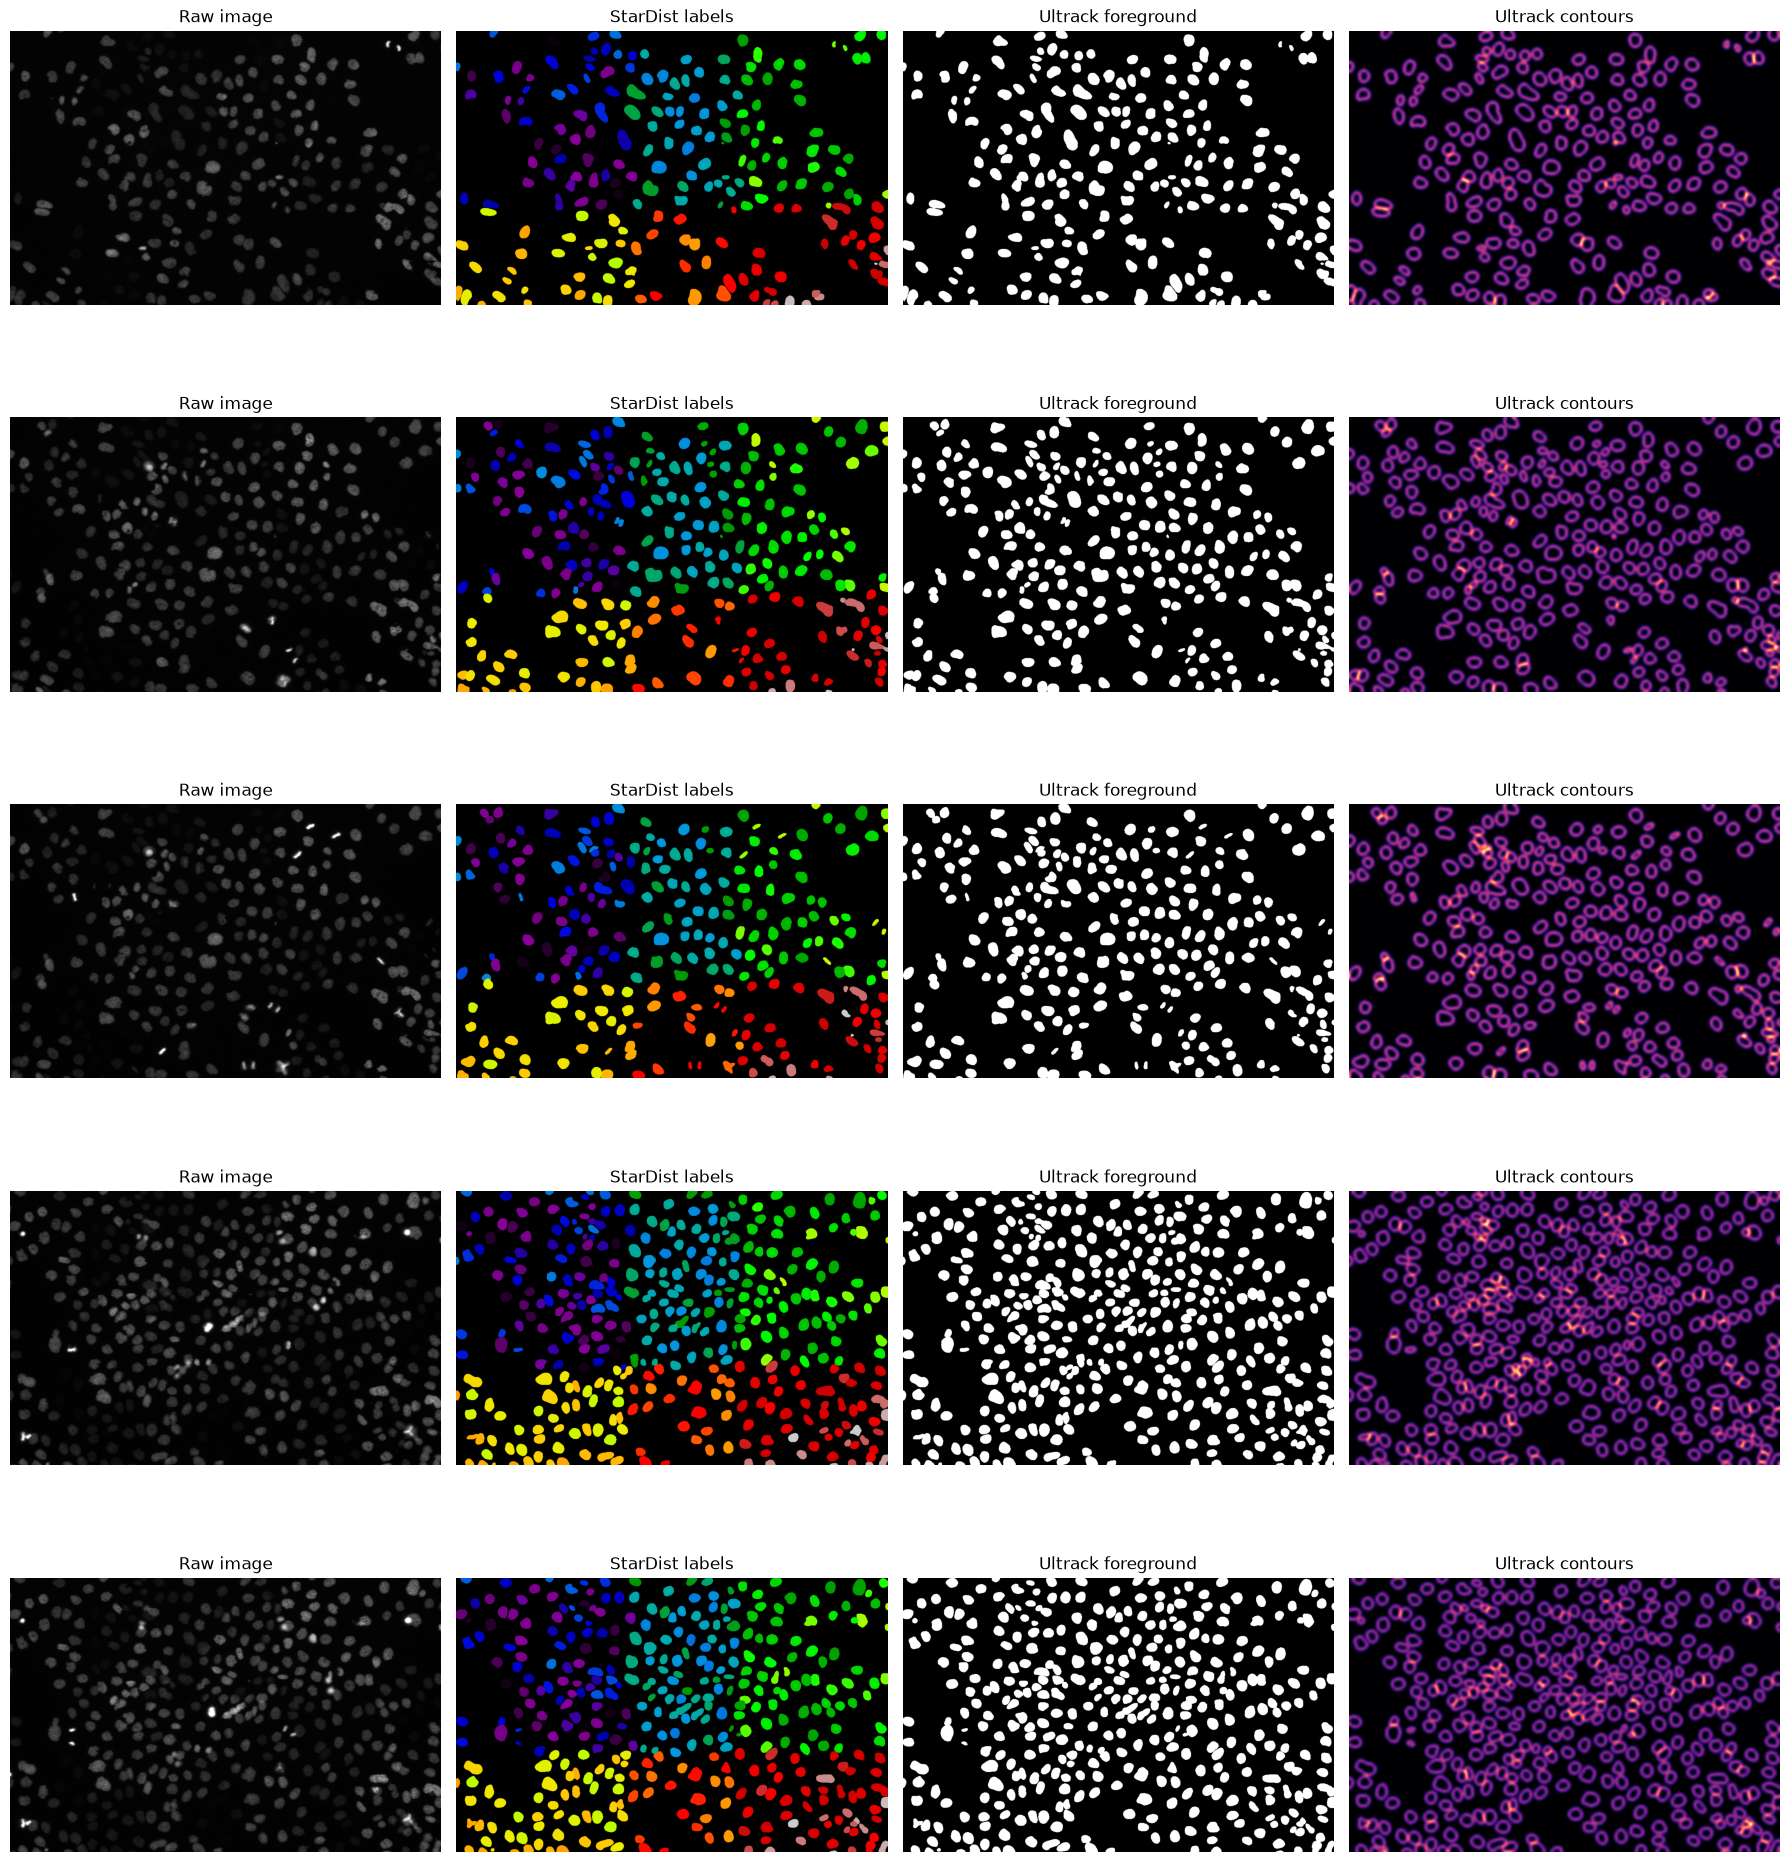

In [14]:
figure, axes = plt.subplots(
    len(display_indices), 4, figsize=(18, 4 * len(display_indices)), squeeze=False
)
for row, index in zip(axes, display_indices):
    row[0].imshow(raw_images[index], cmap="gray")
    row[1].imshow(stardist_labels[index], cmap="nipy_spectral")
    row[2].imshow(foreground[index], cmap="gray")
    row[3].imshow(contours[index], cmap="magma")
    titles = ["Raw image", "StarDist labels", "Ultrack foreground", "Ultrack contours"]
    for axis, title in zip(row, titles):
        axis.set_title(title)
        axis.axis("off")
    row[0].set_ylabel(f"Frame {frame_numbers[index]}")
plt.tight_layout()

In [18]:
# output_path = Path(
#     "../../docs/images/foreground-contours.png"
# )
# output_path.parent.mkdir(parents=True, exist_ok=True)
# figure.savefig(output_path, dpi=150, bbox_inches="tight")

## Run Ultrack

The worker configuration reflects the successful shared-filesystem test:
 
- 4 segmentation workers
- 1 linking worker
- 4 Gurobi threads. 

Each stage remains separate so failures can be diagnosed without rerunning everything


In [15]:
config = MainConfig()
config.data_config.working_dir = RUN_DIR
config.data_config.n_workers = 1
config.segmentation_config.n_workers = 4
config.linking_config.n_workers = 1
config.tracking_config.n_threads = 4
config.tracking_config.solver_name = "GUROBI"

tracker = Tracker(config=config)
runtime_seconds = {}
print(config)

data_config=DataConfig(n_workers=1, working_dir=PosixPath('/net/spaces/clinic/CLS/DSC_CTC/runs/ultrack/hela-seq02-full-stardist'), database_file_name='data.db', database='sqlite', address=None, in_memory_db_id=0) segmentation_config=SegmentationConfig(min_area=100, min_area_factor=4.0, max_area=1000000, n_workers=4, min_frontier=0.0, threshold=0.5, max_noise=0.0, random_seed='frame', ws_hierarchy=<function watershed_hierarchy_by_area at 0x7ab527ee02c0>, anisotropy_penalization=0.0) linking_config=LinkingConfig(max_distance=15.0, n_workers=1, max_neighbors=5, distance_weight=0.0, z_score_threshold=5.0) tracking_config=TrackingConfig(solver_name='GUROBI', appear_weight=-0.001, disappear_weight=-0.001, division_weight=-0.001, image_border_size=None, n_threads=4, window_size=None, overlap_size=1, solution_gap=0.001, time_limit=36000, method=0, link_function='power', power=4, bias=-0.0, dismiss_weight_guess=None, include_weight_guess=None)


### Create segmentation hypotheses

This is Ultrack's segmentation stage; it creates candidate regions based on the foreground and contour maps in the run database. Unlike other methodologies, it creates multiple segmentation hypothesis rather than a single one.


In [16]:
start_time = time.perf_counter()
tracker.segment(foreground=foreground, contours=contours, overwrite=True)
runtime_seconds["ultrack segmentation"] = time.perf_counter() - start_time
print(
    f"Segmentation complete in {runtime_seconds['ultrack segmentation']:.2f} seconds."
)

Adding nodes to database: 100%|██████████| 92/92 [13:08<00:00,  8.57s/it]

Segmentation complete in 796.51 seconds.


### Link candidate segments


In [17]:
start_time = time.perf_counter()
tracker.link(overwrite=True)
runtime_seconds["ultrack linking"] = time.perf_counter() - start_time
print(f"Linking complete in {runtime_seconds['ultrack linking']:.2f} seconds.")

Linking nodes.: 100%|██████████| 91/91 [05:34<00:00,  3.67s/it]

Linking complete in 371.59 seconds.


### Solve the tracking problem

This stage uses the configured Gurobi solver to select a temporally consistent set of segments and links.


In [ ]:
start_time = time.perf_counter()
tracker.solve(overwrite=True)
runtime_seconds["ultrack solving"] = time.perf_counter() - start_time
print(f"Solving complete in {runtime_seconds['ultrack solving']:.2f} seconds.")

## Export and inspect the subset result

- Subset mode exports to `subset_RES`, so it cannot be mistaken for a complete CTC sequence. 

- Full mode exports to `02_RES`, with output frame 000 aligned to original frame 000.

In [19]:
tracks, graph = tracker.to_tracks_layer()
tracks_path = RUN_DIR / "tracks.csv"
segments_path = RUN_DIR / "segments.zarr"
ctc_output_dir = RUN_DIR / CTC_OUTPUT_NAME

tracks.to_csv(tracks_path, index=False)
segments = tracker.to_zarr(store_or_path=segments_path, overwrite=True)
tracker.to_ctc(ctc_output_dir, overwrite=True)

print(f"Track rows: {len(tracks)}")
print(f"Unique tracks: {tracks['track_id'].nunique()}")
print(f"Lineage graph entries: {len(graph)}")
print(f"CTC output: {ctc_output_dir}")
print({name: round(seconds, 2) for name, seconds in runtime_seconds.items()})

Exporting segmentation masks: 100%|██████████| 92/92 [00:02<00:00, 35.16it/s]

Track rows: 26342
Unique tracks: 836
Lineage graph entries: 182
CTC output: /net/spaces/clinic/CLS/DSC_CTC/runs/ultrack/hela-seq02-full-stardist/02_RES
{'ultrack segmentation': 796.51, 'ultrack linking': 371.59, 'ultrack solving': 167.9}


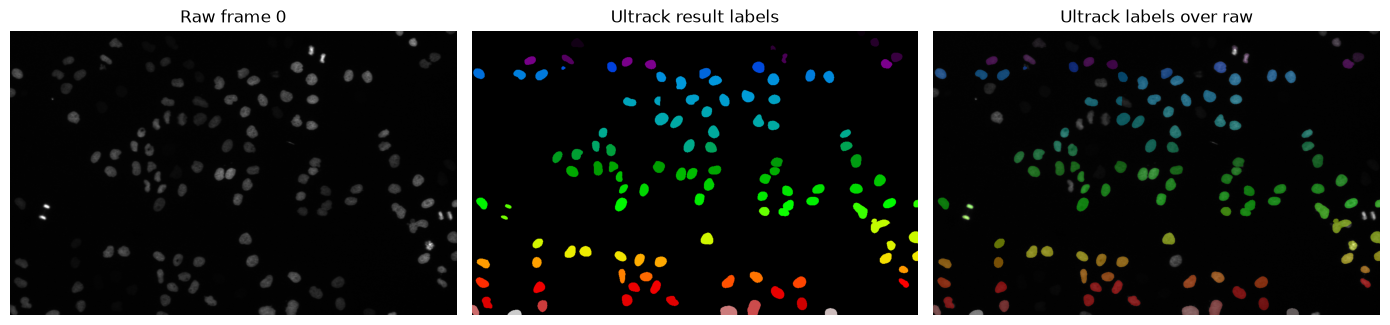

In [20]:
result_index = 0
result_labels = np.asarray(segments[result_index])
figure, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(raw_images[result_index], cmap="gray")
axes[0].set_title(f"Raw frame {frame_numbers[result_index]}")
axes[1].imshow(result_labels, cmap="nipy_spectral")
axes[1].set_title("Ultrack result labels")
axes[2].imshow(raw_images[result_index], cmap="gray")
axes[2].imshow(
    np.ma.masked_where(result_labels == 0, result_labels),
    cmap="nipy_spectral",
    alpha=0.45,
)
axes[2].set_title("Ultrack labels over raw")
for axis in axes:
    axis.axis("off")
plt.tight_layout()

In [25]:
# output_path = Path(
#     "../../docs/images/ultrack-labels-over-rows.png"
# )
# output_path.parent.mkdir(parents=True, exist_ok=True)
# figure.savefig(output_path, dpi=150, bbox_inches="tight")